# **Classificação de texto com spaCy**

## Etapa 1: Importação e instalação das bibliotecas

In [1]:
import os
import random
import string
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from spacy.lang.pt.stop_words import STOP_WORDS

## Etapa 2: Carregamento da base de dados

In [2]:
DRIVE_DIRECTORY = Path.cwd().parent / "data"

In [3]:
base_dados = pd.read_csv(
    os.path.join(DRIVE_DIRECTORY, "base_treinamento.txt"), encoding="utf-8"
)
base_dados

,texto,emocao
0,este trabalho é agradável,alegria
1,gosto de ficar no seu aconchego,alegria
2,fiz a adesão ao curso hoje,alegria
3,eu sou admirada por muitos,alegria
4,adoro como você,alegria
...,...,...
191,estou chocado e amedrontado com este assassina...,medo
192,é preciso afugenta com ímpeto este medo do inf...,medo
193,políticos usam suas forças para afugentar e am...,medo
194,o objetivo disso e apenas me amedrontar mais,medo


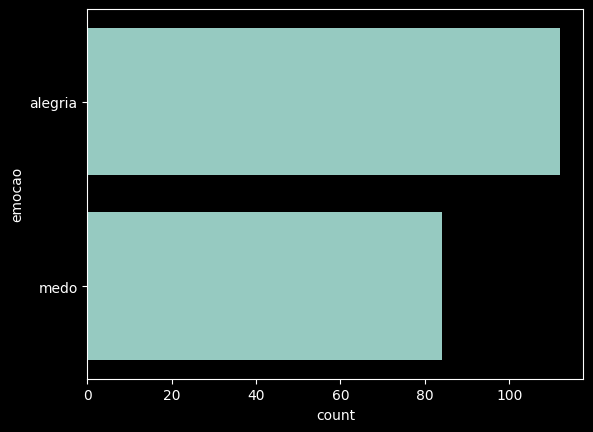

In [4]:
sns.countplot(base_dados["emocao"], label="Contagem");

## Etapa 3: Função para pré-processamento dos textos

In [5]:
pontuacoes = string.punctuation
pontuacoes

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [6]:
stop_words = STOP_WORDS
len(stop_words)

416

In [7]:
pln = spacy.load("pt_core_news_sm")
pln

In [8]:
def preprocessamento(texto):
    texto = texto.lower()
    documento = pln(texto)
    lista = []

    for token in documento:
        lista.append(token.lemma_)

    lista = [
        palavra
        for palavra in lista
        if palavra not in stop_words and palavra not in pontuacoes
    ]
    lista = " ".join([
        str(elemento) for elemento in lista if not elemento.isdigit()
    ])

    return lista

In [9]:
teste = "Estou aprendendo processamento 112233 de linguagem natural, curso em Curitiba"
preprocessamento(teste)

'aprender processamento linguagem natural curso curitber'

## Etapa 4: Pré-processamento da base de dados

### Limpeza dos textos

### Tratamento da classe